In [2]:
import sys, os, warnings, sqlite3
warnings.filterwarnings("ignore")
print("Python:", sys.executable)   # must contain venv\Scripts\python.exe

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Rows before cleaning:", len(df), "| blank TotalCharges:", df["TotalCharges"].isna().sum())
df = df.dropna().reset_index(drop=True)
df["tenure_group"] = pd.cut(df["tenure"], bins=[0, 12, 24, 48, 72],
                            labels=["0-12", "13-24", "25-48", "49+"])
print("Rows after cleaning:", len(df))
print("Overall churn rate:", round((df["Churn"] == "Yes").mean() * 100, 1), "%")
df.head()

Python: C:\Users\sound\customer-churn-analysis\venv\Scripts\python.exe
Rows before cleaning: 7043 | blank TotalCharges: 11
Rows after cleaning: 7032
Overall churn rate: 26.6 %


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_group
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0-12
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,25-48
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,0-12
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,25-48
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,0-12


In [3]:
os.makedirs("../sql", exist_ok=True)
conn = sqlite3.connect("../data/churn.db")
d = df.copy()
d["tenure_group"] = d["tenure_group"].astype(str)
d.to_sql("customers", conn, if_exists="replace", index=False)

rate = "ROUND(100.0 * SUM(CASE WHEN Churn='Yes' THEN 1 ELSE 0 END) / COUNT(*), 1)"

queries = {
"01_churn_by_contract": f"""
SELECT Contract, COUNT(*) AS customers, {rate} AS churn_rate_pct
FROM customers GROUP BY Contract ORDER BY churn_rate_pct DESC;""",

"02_churn_by_tenure": f"""
SELECT tenure_group, COUNT(*) AS customers, {rate} AS churn_rate_pct
FROM customers GROUP BY tenure_group ORDER BY churn_rate_pct DESC;""",

"03_churn_by_tech_support": f"""
SELECT TechSupport, COUNT(*) AS customers, {rate} AS churn_rate_pct
FROM customers WHERE InternetService <> 'No'
GROUP BY TechSupport ORDER BY churn_rate_pct DESC;""",

"04_churn_by_payment_method": f"""
SELECT PaymentMethod, COUNT(*) AS customers, {rate} AS churn_rate_pct
FROM customers GROUP BY PaymentMethod ORDER BY churn_rate_pct DESC;""",

"05_monthly_revenue_lost": """
SELECT Contract,
       COUNT(*) AS churned_customers,
       ROUND(SUM(MonthlyCharges), 0) AS monthly_revenue_lost
FROM customers WHERE Churn = 'Yes'
GROUP BY Contract ORDER BY monthly_revenue_lost DESC;""",

"06_riskiest_segments_cte_window": """
WITH segments AS (
    SELECT Contract, InternetService,
           COUNT(*) AS customers,
           ROUND(100.0 * AVG(CASE WHEN Churn='Yes' THEN 1.0 ELSE 0 END), 1) AS churn_rate_pct,
           ROUND(SUM(CASE WHEN Churn='Yes' THEN MonthlyCharges ELSE 0 END), 0) AS monthly_revenue_lost
    FROM customers
    GROUP BY Contract, InternetService
    HAVING COUNT(*) >= 50
)
SELECT *, RANK() OVER (ORDER BY churn_rate_pct DESC) AS risk_rank
FROM segments ORDER BY risk_rank;""",
}

for name, q in queries.items():
    with open(f"../sql/{name}.sql", "w") as f:
        f.write(q.strip() + "\n")
    print("\n===", name, "===")
    print(pd.read_sql(q, conn).to_string(index=False))


=== 01_churn_by_contract ===
      Contract  customers  churn_rate_pct
Month-to-month       3875            42.7
      One year       1472            11.3
      Two year       1685             2.8

=== 02_churn_by_tenure ===
tenure_group  customers  churn_rate_pct
        0-12       2175            47.7
       13-24       1024            28.7
       25-48       1594            20.4
         49+       2239             9.5

=== 03_churn_by_tech_support ===
TechSupport  customers  churn_rate_pct
         No       3472            41.6
        Yes       2040            15.2

=== 04_churn_by_payment_method ===
            PaymentMethod  customers  churn_rate_pct
         Electronic check       2365            45.3
             Mailed check       1604            19.2
Bank transfer (automatic)       1542            16.7
  Credit card (automatic)       1521            15.3

=== 05_monthly_revenue_lost ===
      Contract  churned_customers  monthly_revenue_lost
Month-to-month               1655

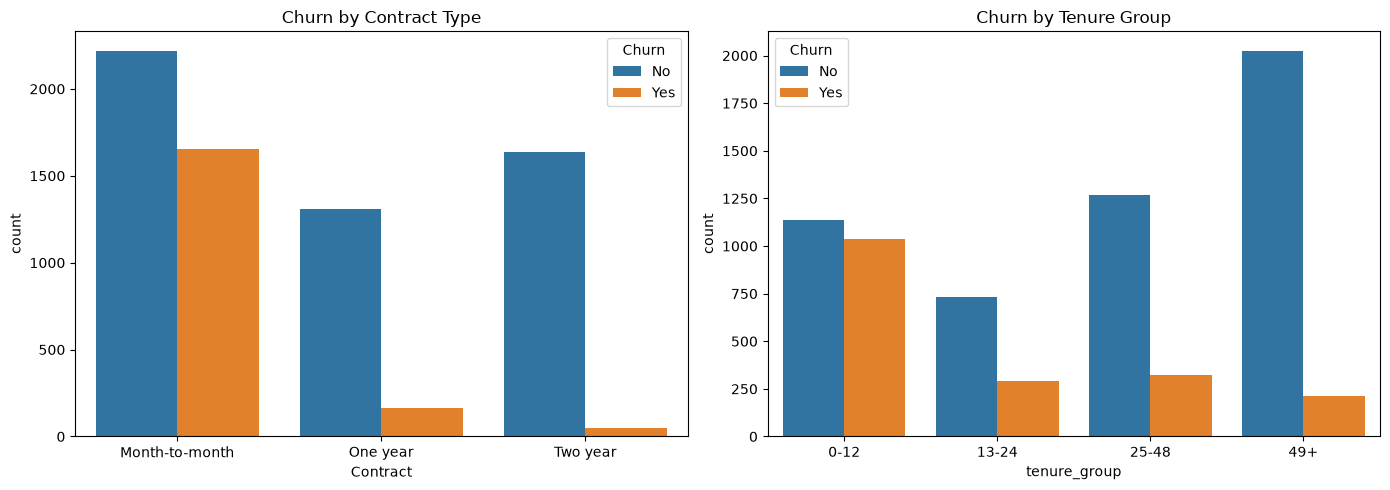

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=df, x="Contract", hue="Churn", ax=axes[0])
axes[0].set_title("Churn by Contract Type")
sns.countplot(data=df, x="tenure_group", hue="Churn", ax=axes[1])
axes[1].set_title("Churn by Tenure Group")
plt.tight_layout()
plt.savefig("../app/churn_charts.png")
plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             classification_report, confusion_matrix)
from xgboost import XGBClassifier

df_model = df.drop(columns=["customerID", "tenure_group"])
df_model = pd.get_dummies(df_model, drop_first=True)
X = df_model.drop(columns=["Churn_Yes"]).astype(float)
y = df_model["Churn_Yes"].astype(int)
print("X:", X.shape, "y:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

spw = (y_train == 0).sum() / (y_train == 1).sum()
models = {
    "Logistic (baseline)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Logistic (balanced)": make_pipeline(StandardScaler(),
                              LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Random Forest (balanced)": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight="balanced",
        random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(
        n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
        colsample_bytree=0.8, scale_pos_weight=spw, eval_metric="logloss",
        random_state=42),
}

rows, probas = {}, {}
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    probas[name] = p
    rows[name] = {"Precision": precision_score(y_test, pred),
                  "Recall": recall_score(y_test, pred),
                  "F1": f1_score(y_test, pred),
                  "ROC-AUC": roc_auc_score(y_test, p)}

results = pd.DataFrame(rows).T.round(3)
results

X: (7032, 30) y: (7032,)


,Precision,Recall,F1,ROC-AUC
Logistic (baseline),0.648,0.575,0.609,0.836
Logistic (balanced),0.491,0.797,0.608,0.835
Random Forest (balanced),0.523,0.789,0.629,0.836
XGBoost,0.500,0.773,0.607,0.830


Model: Random Forest (balanced) | Chosen threshold: 0.50

              precision    recall  f1-score   support

           0       0.91      0.74      0.81      1033
           1       0.52      0.79      0.63       374

    accuracy                           0.75      1407
   macro avg       0.71      0.76      0.72      1407
weighted avg       0.80      0.75      0.77      1407

[[764 269]
 [ 79 295]]

Test customers: 1407 | offers sent: 564 | churners reached: 295
Net benefit targeting with model: $24,960
Net benefit offering to everyone: $-22,161
Assumptions: customer value $778, offer cost $78, success rate 30%


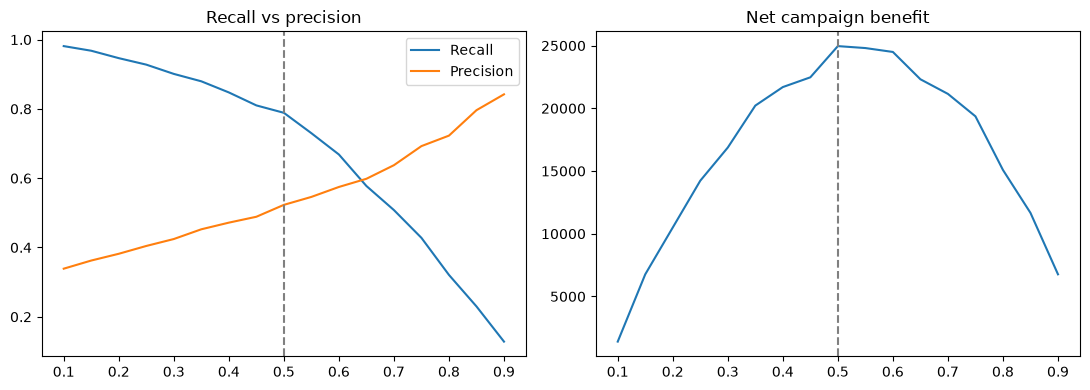

In [6]:
best_name = "Random Forest (balanced)"
probs = probas[best_name]

# ---- ASSUMPTIONS (list these in your README as assumptions, not measured facts) ----
avg_monthly    = df["MonthlyCharges"].mean()
customer_value = avg_monthly * 12          # revenue kept if a churner is saved for 12 months
offer_cost     = avg_monthly * 12 * 0.10   # 10% discount for 12 months
success_rate   = 0.30                      # share of contacted churners the offer saves
# -------------------------------------------------------------------------------------

thresholds = np.arange(0.10, 0.91, 0.05)
benefits, recalls, precisions = [], [], []
for t in thresholds:
    pr = (probs >= t).astype(int)
    tp = ((pr == 1) & (y_test == 1)).sum()
    fp = ((pr == 1) & (y_test == 0)).sum()
    benefits.append(tp * (success_rate * customer_value - offer_cost) - fp * offer_cost)
    recalls.append(recall_score(y_test, pr))
    precisions.append(precision_score(y_test, pr, zero_division=0))

best_t = float(thresholds[int(np.argmax(benefits))])
final_pred = (probs >= best_t).astype(int)
print(f"Model: {best_name} | Chosen threshold: {best_t:.2f}\n")
print(classification_report(y_test, final_pred))
print(confusion_matrix(y_test, final_pred))

tp = int(((final_pred == 1) & (y_test == 1)).sum())
fp = int(((final_pred == 1) & (y_test == 0)).sum())
model_net = tp * success_rate * customer_value - (tp + fp) * offer_cost
all_net   = y_test.sum() * success_rate * customer_value - len(y_test) * offer_cost
print(f"\nTest customers: {len(y_test)} | offers sent: {tp + fp} | churners reached: {tp}")
print(f"Net benefit targeting with model: ${model_net:,.0f}")
print(f"Net benefit offering to everyone: ${all_net:,.0f}")
print(f"Assumptions: customer value ${customer_value:,.0f}, offer cost ${offer_cost:,.0f}, "
      f"success rate {success_rate:.0%}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(thresholds, recalls, label="Recall")
ax[0].plot(thresholds, precisions, label="Precision")
ax[0].axvline(best_t, ls="--", color="grey"); ax[0].legend(); ax[0].set_title("Recall vs precision")
ax[1].plot(thresholds, benefits); ax[1].axvline(best_t, ls="--", color="grey")
ax[1].set_title("Net campaign benefit")
plt.tight_layout(); plt.show()

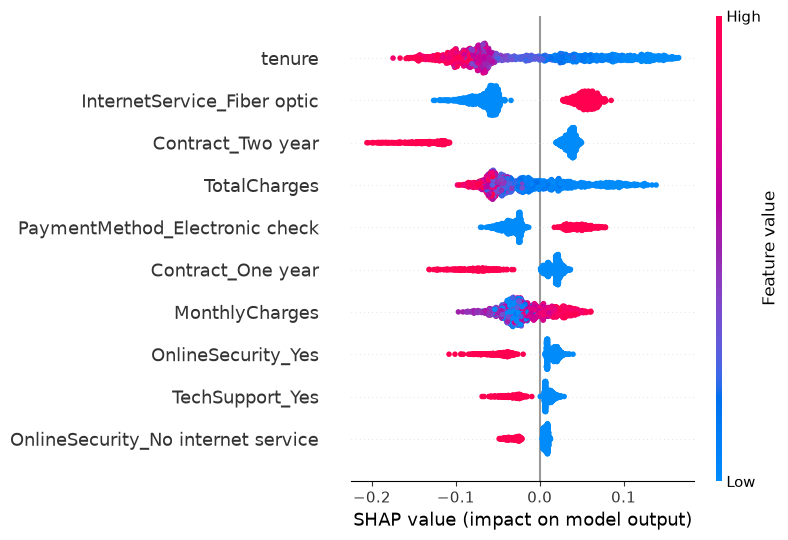

In [7]:
import shap

rf = models["Random Forest (balanced)"]
explainer = shap.TreeExplainer(rf)
sv = explainer.shap_values(X_test)
if isinstance(sv, list):
    sv_churn = sv[1]
elif sv.ndim == 3:
    sv_churn = sv[:, :, 1]
else:
    sv_churn = sv

shap.summary_plot(sv_churn, X_test, max_display=10)

In [8]:
pred_df = pd.DataFrame({
    "customerID": df.loc[X_test.index, "customerID"].values,
    "churn_probability": probs.round(4),
    "high_risk": (probs >= best_t).astype(int),
    "actual_churn": y_test.values,
})
pred_df.to_sql("predictions", conn, if_exists="replace", index=False)

q = """
SELECT p.customerID, ROUND(p.churn_probability, 3) AS churn_probability,
       c.Contract, c.TechSupport, c.MonthlyCharges
FROM predictions p JOIN customers c USING (customerID)
WHERE p.high_risk = 1
ORDER BY p.churn_probability DESC, c.MonthlyCharges DESC
LIMIT 10;"""
with open("../sql/07_top_high_risk_customers.sql", "w") as f:
    f.write(q.strip() + "\n")
pd.read_sql(q, conn)

,customerID,churn_probability,Contract,TechSupport,MonthlyCharges
0,1820-TQVEV,0.973,Month-to-month,No,69.55
1,5542-TBBWB,0.971,Month-to-month,No,69.90
2,9804-ICWBG,0.971,Month-to-month,No,69.90
3,3716-BDVDB,0.966,Month-to-month,No,69.10
4,9057-SIHCH,0.962,Month-to-month,No,96.60
5,6861-XWTWQ,0.962,Month-to-month,No,99.25
6,5178-LMXOP,0.962,Month-to-month,No,95.10
7,1069-XAIEM,0.961,Month-to-month,No,85.05
8,5150-ITWWB,0.959,Month-to-month,No,94.85
9,8375-DKEBR,0.958,Month-to-month,No,69.60


In [9]:
ALLOWED_OFFERS = [
    "Discounted 12-month contract upgrade",
    "Free 3-month tech support trial",
    "Autopay switch incentive",
    "Service quality check-in call",
    "Loyalty thank-you call (no discount)",
]

def top_drivers(i, k=4):
    contrib = pd.Series(sv_churn[i], index=X_test.columns)
    top = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(k)
    return [f"{feat} ({'raises' if v > 0 else 'lowers'} churn risk)" for feat, v in top.items()]

def template_recommendation(row):
    if row["Contract"] == "Month-to-month":
        return ALLOWED_OFFERS[0]
    if row["InternetService"] != "No" and row["TechSupport"] == "No":
        return ALLOWED_OFFERS[1]
    if row["PaymentMethod"] == "Electronic check":
        return ALLOWED_OFFERS[2]
    if row["InternetService"] == "Fiber optic":
        return ALLOWED_OFFERS[3]
    return ALLOWED_OFFERS[4]

def recommend(prob, drivers, row):
    key = os.getenv("ANTHROPIC_API_KEY")
    if not key:
        return template_recommendation(row) + "  [template fallback]"
    try:
        import anthropic
        client = anthropic.Anthropic(api_key=key)
        prompt = (
            f"A telecom customer has a {prob:.0%} churn probability.\n"
            f"Top model drivers: {'; '.join(drivers)}.\n"
            f"Choose exactly ONE offer from this list and justify it in one sentence "
            f"using only the drivers above. Do not invent discounts or offers.\n"
            f"Allowed offers: {ALLOWED_OFFERS}"
        )
        msg = client.messages.create(model="claude-sonnet-5-5", max_tokens=150,
                                     messages=[{"role": "user", "content": prompt}])
        return msg.content[0].text.strip()
    except Exception:
        return template_recommendation(row) + "  [template fallback]"

order = np.argsort(-probs)[:5]
out = []
for i in order:
    row = df.loc[X_test.index[i]]
    drv = top_drivers(i)
    out.append({"customerID": row["customerID"], "churn_probability": round(float(probs[i]), 3),
                "top_drivers": " | ".join(drv),
                "recommendation": recommend(float(probs[i]), drv, row)})

recs = pd.DataFrame(out)
recs.to_csv("../data/sample_recommendations.csv", index=False)
recs

,customerID,churn_probability,top_drivers,recommendation
0,1820-TQVEV,0.973,tenure (raises churn risk) | TotalCharges (raises churn risk) | InternetService_Fiber optic (raises churn risk) | Contract_Two year (raises churn risk),Discounted 12-month contract upgrade [template fallback]
1,5542-TBBWB,0.971,tenure (raises churn risk) | TotalCharges (raises churn risk) | InternetService_Fiber optic (raises churn risk) | Contract_Two year (raises churn risk),Discounted 12-month contract upgrade [template fallback]
2,9804-ICWBG,0.971,tenure (raises churn risk) | TotalCharges (raises churn risk) | InternetService_Fiber optic (raises churn risk) | Contract_Two year (raises churn risk),Discounted 12-month contract upgrade [template fallback]
3,3716-BDVDB,0.966,tenure (raises churn risk) | TotalCharges (raises churn risk) | InternetService_Fiber optic (raises churn risk) | PaymentMethod_Electronic check (raises churn risk),Discounted 12-month contract upgrade [template fallback]
4,9057-SIHCH,0.962,tenure (raises churn risk) | InternetService_Fiber optic (raises churn risk) | Contract_Two year (raises churn risk) | MonthlyCharges (raises churn risk),Discounted 12-month contract upgrade [template fallback]


In [10]:
import os
import numpy as np
import pandas as pd

pd.set_option("display.max_colwidth", None)

# Cell 6 must have been run on the FULL X_test, so SHAP rows line up with X_test rows
assert sv_churn.shape[0] == len(X_test), "Re-run Cell 6 on the full X_test (not the sampled version)."

ALLOWED_OFFERS = [
    "Discounted 12-month contract upgrade",
    "Free 3-month tech support trial",
    "Autopay switch incentive",
    "Service quality check-in call",
    "Loyalty thank-you call (no discount)",
]

def driver_series(i):
    """SHAP contributions for test row i (positive = pushes churn risk up)."""
    return pd.Series(sv_churn[i], index=X_test.columns)

def top_drivers_text(i, k=4):
    c = driver_series(i)
    top = c.reindex(c.abs().sort_values(ascending=False).index).head(k)
    return [f"{feat} ({'raises' if v > 0 else 'lowers'} churn risk)" for feat, v in top.items()]

def template_recommendation(i, row):
    """Rule-based fallback: follow the strongest risk-raising driver that maps to an offer."""
    c = driver_series(i)
    for feat in c[c > 0].sort_values(ascending=False).index:
        if feat == "tenure" or feat == "TotalCharges" or feat.startswith("Contract_"):
            if row["Contract"] == "Month-to-month":
                return ALLOWED_OFFERS[0]
        elif feat in ("TechSupport_Yes", "OnlineSecurity_Yes"):
            if row["InternetService"] != "No" and row["TechSupport"] == "No":
                return ALLOWED_OFFERS[1]
        elif feat.startswith("PaymentMethod_Electronic"):
            if row["PaymentMethod"] == "Electronic check":
                return ALLOWED_OFFERS[2]
        elif feat in ("InternetService_Fiber optic", "MonthlyCharges"):
            if row["InternetService"] == "Fiber optic":
                return ALLOWED_OFFERS[3]
    return ALLOWED_OFFERS[4]

# ---- LLM client (optional; works without a key) ----
client = None
if os.getenv("ANTHROPIC_API_KEY"):
    try:
        import anthropic
        client = anthropic.Anthropic()
    except Exception as e:
        print("Anthropic client unavailable, using template fallback:", e)

def recommend(i, prob, drivers, row):
    fallback = template_recommendation(i, row)
    if client is None:
        return fallback, "template"
    prompt = (
        f"A telecom customer has a {prob:.0%} churn probability.\n"
        f"Top model drivers: {'; '.join(drivers)}.\n\n"
        f"Choose exactly ONE offer from the allowed list and justify it in one sentence "
        f"using only the drivers above. Do not invent discounts, prices or offers.\n"
        f"Allowed offers: {ALLOWED_OFFERS}\n\n"
        f"Reply in exactly this format:\nOffer: <offer from the list>\nReason: <one sentence>"
    )
    try:
        msg = client.messages.create(model="claude-sonnet-5-5", max_tokens=150,
                                     messages=[{"role": "user", "content": prompt}])
        text = msg.content[0].text.strip()
        if any(o in text for o in ALLOWED_OFFERS):      # reject anything off-list
            return text.replace("\n", " | "), "LLM"
    except Exception:
        pass
    return fallback, "template"

# ---- pick the top-risk customer from each contract + internet segment ----
hi = np.where(probs >= best_t)[0]
tmp = pd.DataFrame({
    "i": hi,
    "p": probs[hi],
    "segment": [df.loc[X_test.index[j], "Contract"] + " | " + df.loc[X_test.index[j], "InternetService"]
                for j in hi],
})
order = (tmp.sort_values("p", ascending=False)
            .groupby("segment").head(1)
            .sort_values("p", ascending=False)
            .head(5)["i"].tolist())

out = []
for i in order:
    row = df.loc[X_test.index[i]]
    drv = top_drivers_text(i)
    rec, source = recommend(i, float(probs[i]), drv, row)
    out.append({
        "customerID": row["customerID"],
        "segment": f'{row["Contract"]} | {row["InternetService"]}',
        "churn_probability": round(float(probs[i]), 3),
        "top_drivers": " | ".join(drv),
        "recommendation": rec,
        "source": source,
    })

recs = pd.DataFrame(out)
recs.to_csv("../data/sample_recommendations.csv", index=False)
recs

,customerID,segment,churn_probability,top_drivers,recommendation,source
0,1820-TQVEV,Month-to-month | Fiber optic,0.973,tenure (raises churn risk) | TotalCharges (raises churn risk) | InternetService_Fiber optic (raises churn risk) | Contract_Two year (raises churn risk),Discounted 12-month contract upgrade,template
1,0841-NULXI,Month-to-month | DSL,0.942,tenure (raises churn risk) | TotalCharges (raises churn risk) | PaymentMethod_Electronic check (raises churn risk) | InternetService_Fiber optic (lowers churn risk),Discounted 12-month contract upgrade,template
2,1240-KNSEZ,Month-to-month | No,0.717,tenure (raises churn risk) | TotalCharges (raises churn risk) | InternetService_Fiber optic (lowers churn risk) | Contract_Two year (raises churn risk),Discounted 12-month contract upgrade,template
3,6362-QHAFM,One year | Fiber optic,0.692,Contract_One year (lowers churn risk) | PaymentMethod_Electronic check (raises churn risk) | InternetService_Fiber optic (raises churn risk) | MonthlyCharges (raises churn risk),Autopay switch incentive,template
4,4905-JEFDW,One year | DSL,0.604,Contract_One year (lowers churn risk) | PaymentMethod_Electronic check (raises churn risk) | InternetService_Fiber optic (lowers churn risk) | tenure (raises churn risk),Autopay switch incentive,template
